# 07 · Project 2 starts here: node features for the graph neural networks

Notebook 06 ended with the plan: test whether the honest networks actually improve predictions. Before any model can be trained, every stay (one dot in the network) needs **numbers describing it**. This notebook decides what those numbers are, for both questions, and checks which of them carry signal.

Peeking can sneak in two ways: through *which stays are linked* (the network) and through *what each stay is described by* (the features). So we build every combination:

| | features: honest | features: cheating |
|---|---|---|
| **network: honest** | the one you could really use | cheating features only |
| **network: cheating** | cheating links only | everything cheats |
| **network: random** | control: real features, meaningless links | |

Nothing here is computed from the outcomes. **No train/test split is made yet**; each stay's patient is kept so one can be added later without splitting a patient across sets.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
# import sys
# import os

# sys.path.insert(0, os.path.abspath('//wsl.localhost/Ubuntu/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/src'))

from ehrgraph.eval.aggregate import write_aggregate
from ehrgraph.gnn.node_features import (
    FEATURE_SETS, LEAKABLE_BLOCKS, ablation_rows, block_ablation, build_pyg_data, check_data,
    code_gap_table, column_auroc, make_blocks, top_codes,
)
from ehrgraph.netstats.task_analysis import PRIMARY_VARIANT, analyze_task, task_graphs_from_labels
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()  # finds the data in data/omop/

nf.apply_style()
TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
NAME = {"safe": "honest", "leaky": "cheating", "null": "random"}   # the report's words
CLMBR_PATH = None   # full release only: Path(ASSETS) / "features" / "clmbr_features.pkl"
                    # with None the CLMBR parts are simply skipped

data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate


## Rebuild the networks

Notebooks 02 and 03 only save summary numbers (no patient data), so the networks are rebuilt here. We keep one random network per question (`n_null=1`), which is all this notebook needs. This takes a few minutes per question.

In [2]:
nets, results, y, groups = {}, {}, {}, {}
for task in TASKS:
    # nets[task] = task_graphs_from_labels(p.diagnoses, p.labels(task), task)
    nets[task] = task_graphs_from_labels(p.diagnoses, p.labels(task), task,
                                         clmbr_path=CLMBR_PATH, n_null=1)
    results[task] = analyze_task(nets[task])      # supplies centralities and groups
    tg = nets[task]
    y[task] = np.array([tg.labels[n] for n in tg.nodes])
    groups[task] = pd.factorize(pd.Series([n[0] for n in tg.nodes]))[0]    # one id per patient
    print(f"{TASKS[task]}: {len(tg.nodes):,} stays, {tg.prevalence:.1%} with the outcome, "
          f"CLMBR on {len(tg.feature_nodes):,} stays")

long stay: 6,998 stays, 25.4% with the outcome, CLMBR on 0 stays
new high blood pressure: 3,511 stays, 12.8% with the outcome, CLMBR on 0 stays


## What describes a stay?

Each description is a named block of numbers:

| block | what it is | needs the network? | can cheat? |
|---|---|---|---|
| `dx_svd` | the stay's diagnoses, rare ones weighted up, squeezed into 64 numbers | no | yes, if fed the whole record |
| `dx_summary` | how many different diagnoses the stay has (cheating stays have about twice as many) | no | yes |
| `structure` | how many links, how many closed triangles, how central, how many links to the same patient | yes | through the links |
| `rwpe` | how likely a short random walk is to come back to the stay (a "role in the neighbourhood" number) | yes | through the links |
| `n2v` | **node2vec**: random walks around the network, then 64 numbers learned so that stays that appear near each other get similar numbers | yes | through the links |
| `clmbr` | Stanford's pretrained patient summary at the prediction time | no | should not (to verify) |
| `time` | prediction year (only used as a check, because of the 2015 code switch) | no | no |

node2vec uses 10 walks of length 30 per stay, a context window of 5, 5 noise samples per pair, and unbiased walks (`p = q = 1`). Those two knobs can be swept later.

In [3]:
GRID = [("safe", "safe"), ("safe", "leaky"), ("leaky", "safe"), ("leaky", "leaky"), ("null", "safe")]
N2V = dict(dim=64, num_walks=10, walk_length=30, window=5, negatives=5, epochs=5, p=1.0, q=1.0)

blocks, n2v_cache = {}, {}
for task, tg in nets.items():
    n2v_cache[task] = {}      # node2vec depends on the network only: train once per network
    blocks[task] = {
        (g, s): make_blocks(tg, g, s, centrality=results[task].centrality[g], svd_dim=64,
                            rw_steps=8, n2v=N2V, n2v_cache=n2v_cache[task])
        for g, s in GRID
    }

for task in TASKS:
    print(TASKS[task], {k: v.values.shape[1] for k, v in blocks[task][("safe", "safe")].items()})
    print("   stays with no links (node2vec can't walk from them, they get zeros):",
          {NAME[g]: f"{b.meta['isolated']:,}" for g, b in n2v_cache[task].items()})

long stay {'dx_svd': 64, 'dx_summary': 1, 'time': 1, 'structure': 7, 'rwpe': 8, 'n2v': 65}
   stays with no links (node2vec can't walk from them, they get zeros): {'honest': '301', 'cheating': '539', 'random': '301'}
new high blood pressure {'dx_svd': 64, 'dx_summary': 1, 'time': 1, 'structure': 7, 'rwpe': 8, 'n2v': 65}
   stays with no links (node2vec can't walk from them, they get zeros): {'honest': '172', 'cheating': '262', 'random': '172'}


In [4]:
# what an honest "diagnosis axis" means, in real diagnoses (first three axes, long stay)
task = "guo_los"
for c in range(3):
    tc = top_codes(blocks[task][("safe", "safe")]["dx_svd"], c, n=8)
    print(f"axis {c}"); display(tc.assign(diagnosis=tc.code.map(p.names(tc.code)))[["diagnosis", "loading"]])

axis 0


,diagnosis,loading
0,Essential hypertension,0.171166
1,Hyperlipidemia,0.154760
2,Electrocardiogram abnormal,0.139112
3,Type 2 diabetes mellitus without complication,0.118993
4,Anemia,0.112815
5,Lung field abnormal,0.107729
6,Dyspnea,0.107696
7,Pleural effusion,0.105698


axis 1


,diagnosis,loading
0,Single live birth,0.343018
1,Finding related to pregnancy,0.323212
2,Third trimester pregnancy,0.250134
3,Unplanned pregnancy,0.211807
4,Disorder of pregnancy,0.192140
5,"Gestation period, 39 weeks",0.188106
6,High risk pregnancy,0.179713
7,Maternal AND/OR fetal condition affecting labo...,0.176932


axis 2


,diagnosis,loading
0,Congestive heart failure,0.199631
1,Hyperlipidemia,0.179137
2,Atrial fibrillation,0.146604
3,Essential hypertension,0.134753
4,Fever,-0.129350
5,Atherosclerosis of coronary artery without ang...,0.123498
6,Coronary atherosclerosis,0.123291
7,Coronary arteriosclerosis,0.122142


### Does node2vec reflect the network?

Cosine similarity (1 = same direction) between node2vec numbers for two stays in the **same Leiden group** vs. two random stays. Honest and cheating networks should show a clear gap. The random network, which has no group structure, should show almost none. The numbers are only comparable *within* one network, so read each row on its own.

In [5]:
rng = np.random.default_rng(0)
rows = []
for task, tg in nets.items():
    for g in ("safe", "leaky", "null"):
        b = n2v_cache[task][g].values
        z, ok = b[:, :-1], b[:, -1] == 0
        part = results[task].communities[g]["leiden"].to_dict()
        comm = np.array([part.get(n, -1) for n in tg.nodes])
        zn = z / np.clip(np.linalg.norm(z, axis=1, keepdims=True), 1e-9, None)
        idx = np.flatnonzero(ok & (comm >= 0))
        a, c = rng.choice(idx, 20000), rng.choice(idx, 20000)
        same = (comm[a] == comm[c]) & (a != c)
        cos = (zn[a] * zn[c]).sum(1)
        rows.append({"question": TASKS[task], "network": NAME[g],
                     "same group": cos[same].mean(), "different groups": cos[~same].mean()})
pd.DataFrame(rows).set_index(["question", "network"]).round(2)

same group  different groups
question                network                               
long stay               honest          0.54              0.34
                        cheating        0.57              0.37
                        random          0.25              0.22
new high blood pressure honest          0.58              0.34
                        cheating        0.61              0.36
                        random          0.26              0.21

## CLMBR next to the networks

CLMBR is our honest reference, so first: how does it relate to each network? `dirichlet_energy_clmbr` (from the analysis in notebooks 02 and 03) measures how different CLMBR's numbers are across a network's links. **Lower means linked stays look more alike to CLMBR.** If the honest network sits well below the random one, our diagnosis network and CLMBR agree on what a "similar patient" is.

In [6]:
if CLMBR_PATH is None:
    print("No CLMBR in this run (CLMBR_PATH is None).")
else:
    clmbr = pd.concat({
        TASKS[t]: pd.DataFrame([r for r in results[t].rows
                                if r["metric"] in ("dirichlet_energy_clmbr", "clmbr_coverage")])
        .pivot_table(index="metric", columns="condition", values="value")
        for t in TASKS
    })
    display(clmbr.round(3))

No CLMBR in this run (CLMBR_PATH is None).


## Which features matter?

Three views, finest to coarsest. They are **descriptive** (they use all outcomes, like the homophily numbers in notebooks 02 and 03) and involve no neural network.

1. **Diagnoses:** how often do positive vs. negative stays have each diagnosis? This is where a leak shows up *by name*.
2. **Single numbers:** how well does each network-based number alone separate the outcome? (0.5 = not at all.)
3. **Blocks:** a simple tree model on each block alone, and on everything *except* that block. The score is always measured on patients the model hasn't seen (a patient's other stays never sit in the test fold), so a patient can't be recognised from their own other stay.

One cheating diagnosis can get watered down inside 64 mixed numbers, so view 1 is the direct detector and view 3 shows what survives.

In [7]:
for task, tg in nets.items():
    for s in ("safe", "leaky"):
        matrix, codes = tg.vectors[s]
        gap = code_gap_table(matrix, codes, y[task], top=8)
        print(f"--- {TASKS[task]}: biggest differences, {NAME[s]} diagnoses")
        display(gap.assign(diagnosis=gap.code.map(p.names(gap.code)))
                [["diagnosis", "positive_rate", "negative_rate", "gap"]].round(2))

--- long stay: biggest differences, honest diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Acute renal failure syndrome,0.33,0.15,0.19
1,Pleural effusion,0.33,0.17,0.16
2,Acute posthemorrhagic anemia,0.28,0.14,0.14
3,Atrial fibrillation,0.24,0.12,0.12
4,Acidosis,0.18,0.07,0.12
5,Hypervolemia,0.17,0.06,0.11
6,Thrombocytopenic disorder,0.22,0.10,0.11
7,Congestive heart failure,0.24,0.13,0.11


--- long stay: biggest differences, cheating diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Pleural effusion,0.63,0.37,0.27
1,Acute renal failure syndrome,0.50,0.28,0.21
2,Atelectasis,0.53,0.31,0.21
3,Sepsis,0.38,0.21,0.17
4,Cardiomegaly,0.43,0.27,0.17
5,Hypervolemia,0.30,0.13,0.17
6,Electrocardiogram abnormal,0.73,0.57,0.16
7,Ascites,0.32,0.16,0.16


--- new high blood pressure: biggest differences, honest diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Single live birth,0.03,0.14,-0.11
1,Finding related to pregnancy,0.04,0.15,-0.11
2,Hyperlipidemia,0.24,0.14,0.11
3,Hypo-osmolality and or hyponatremia,0.17,0.07,0.10
4,Cardiomegaly,0.19,0.09,0.10
5,Congestive heart failure,0.17,0.07,0.10
6,Electrocardiogram abnormal,0.33,0.24,0.09
7,Pleural effusion,0.25,0.15,0.09


--- new high blood pressure: biggest differences, cheating diagnoses


,diagnosis,positive_rate,negative_rate,gap
0,Essential hypertension,1.00,0.13,0.87
1,Hyperlipidemia,0.64,0.27,0.37
2,Pleural effusion,0.58,0.29,0.29
3,Acute renal failure syndrome,0.48,0.20,0.28
4,Cardiomegaly,0.42,0.15,0.27
5,Anemia,0.62,0.36,0.26
6,Electrocardiogram abnormal,0.69,0.43,0.26
7,Dyspnea,0.55,0.30,0.25


In [8]:
for task in TASKS:
    print(TASKS[task]); display(column_auroc(blocks[task][("safe", "safe")]["structure"], y[task]).round(3))

long stay


,column,auroc
0,eigenvector_pct,0.528
1,log_degree,0.472
2,n_same_patient_neighbors,0.522
3,core_number,0.482
4,clustering,0.492
5,closeness_pct,0.504
6,betweenness_pct,0.498


new high blood pressure


,column,auroc
0,closeness_pct,0.590
1,eigenvector_pct,0.575
2,n_same_patient_neighbors,0.430
3,betweenness_pct,0.534
4,clustering,0.470
5,log_degree,0.494
6,core_number,0.499


In [9]:
NAMES = ["dx_svd", "dx_summary", "structure", "rwpe", "n2v", "time", "clmbr"]   # missing blocks are skipped
ABLATE = GRID      # a few minutes per question; try [("safe","safe"), ("leaky","leaky")] for a first look

ablation, alone = {}, {}
for task in TASKS:
    ablation[task] = {(g, s): block_ablation(blocks[task][(g, s)], NAMES, y[task], groups[task])
                      for g, s in ABLATE}
    alone[task] = pd.concat(
        {f"network: {NAME[g]} | features: {NAME[s]}": t.set_index("block")["alone_auroc"]
         for (g, s), t in ablation[task].items()}, axis=1)
    print(TASKS[task], "- how well each block alone predicts (0.5 = not at all)")
    display(alone[task].round(3))
    print("   how much the best score drops without that block")
    display(pd.concat({f"network: {NAME[g]} | features: {NAME[s]}":
                       t.set_index("block")["auroc_lost_when_dropped"]
                       for (g, s), t in ablation[task].items()}, axis=1).round(3))

long stay - how well each block alone predicts (0.5 = not at all)


,network: honest | features: honest,network: honest | features: cheating,network: cheating | features: honest,network: cheating | features: cheating,network: random | features: honest
block,,,,,
ALL,0.778,0.773,0.773,0.758,0.767
dx_svd,0.773,0.756,0.773,0.756,0.773
dx_summary,0.572,0.589,0.572,0.589,0.572
structure,0.581,0.581,0.584,0.584,0.515
rwpe,0.535,0.535,0.528,0.528,0.493
n2v,0.703,0.703,0.668,0.668,0.511
time,0.520,0.520,0.520,0.520,0.520


   how much the best score drops without that block


,network: honest | features: honest,network: honest | features: cheating,network: cheating | features: honest,network: cheating | features: cheating,network: random | features: honest
block,,,,,
ALL,NaN,NaN,NaN,NaN,NaN
dx_svd,0.054,0.048,0.087,0.075,0.191
dx_summary,-0.001,0.005,0.002,0.009,-0.001
structure,-0.001,0.011,0.003,0.004,-0.001
rwpe,0.001,0.004,0.002,0.001,-0.001
n2v,-0.001,0.003,-0.003,-0.007,-0.009
time,0.001,0.004,-0.000,0.005,0.002


new high blood pressure - how well each block alone predicts (0.5 = not at all)


,network: honest | features: honest,network: honest | features: cheating,network: cheating | features: honest,network: cheating | features: cheating,network: random | features: honest
block,,,,,
ALL,0.674,0.841,0.707,0.828,0.644
dx_svd,0.660,0.838,0.660,0.838,0.660
dx_summary,0.554,0.653,0.554,0.653,0.554
structure,0.587,0.587,0.525,0.525,0.519
rwpe,0.519,0.519,0.503,0.503,0.504
n2v,0.623,0.623,0.651,0.651,0.453
time,0.629,0.629,0.629,0.629,0.629


   how much the best score drops without that block


,network: honest | features: honest,network: honest | features: cheating,network: cheating | features: honest,network: cheating | features: cheating,network: random | features: honest
block,,,,,
ALL,NaN,NaN,NaN,NaN,NaN
dx_svd,0.018,0.086,0.017,0.054,0.100
dx_summary,-0.005,0.007,-0.004,-0.000,0.001
structure,0.019,0.019,0.020,0.010,-0.015
rwpe,-0.007,-0.006,0.012,0.005,-0.003
n2v,-0.019,-0.015,0.022,-0.014,-0.006
time,0.005,-0.001,0.016,0.001,0.010


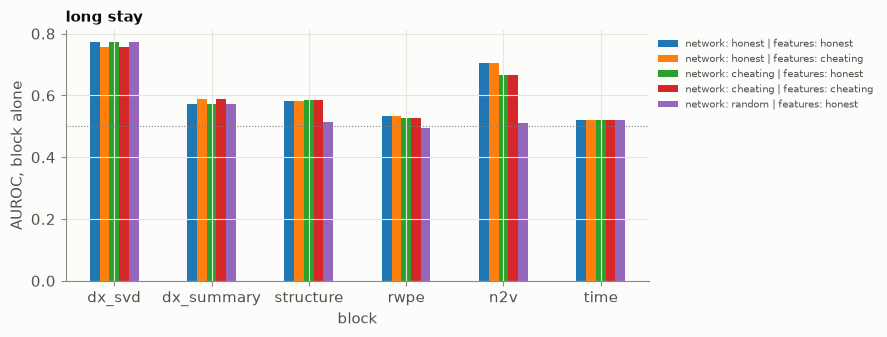

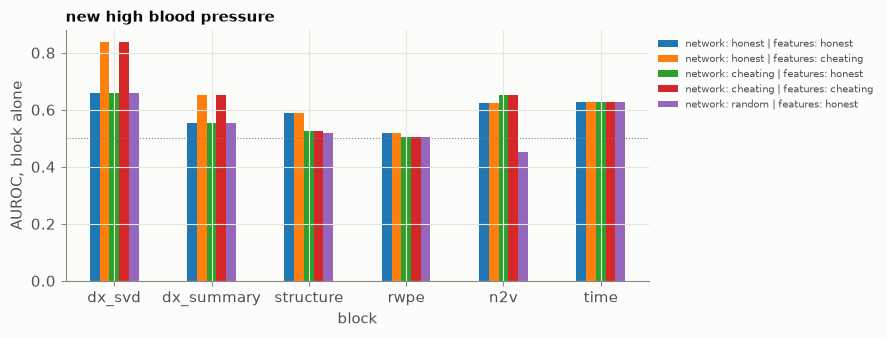

In [10]:
for task in TASKS:
    ax = alone[task].drop(index="ALL").plot.bar(figsize=(9, 3.5), rot=0, title=TASKS[task])
    ax.axhline(0.5, color="grey", lw=0.8, ls=":"); ax.set_ylabel("AUROC, block alone")
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout()
    nf.save(ax.figure, p.figures / f"07_feature_blocks_{task}.png")
    plt.show()

## Build the inputs for the neural networks

One `Data` object per combination (network, features, feature set). Feature sets that don't use diagnoses (`structure`, `n2v`, `clmbr`, `clmbr_n2v`) ignore the feature version, so only the honest one is built for them. The numbers are **not yet scaled**: scaling must use only training stays, so it waits for the split (`standardize`).

In [11]:
datasets = {}
for task, tg in nets.items():
    datasets[task] = {}
    for g, s in GRID:
        for fs, names in FEATURE_SETS.items():
            if not any(n in LEAKABLE_BLOCKS for n in names) and s == "leaky":
                continue                      # identical to the honest-features version
            if not all(n in blocks[task][(g, s)] for n in names):
                continue                      # e.g. clmbr without the full release
            datasets[task][(g, s, fs)] = build_pyg_data(tg, g, s, fs, blocks=blocks[task][(g, s)])
    for d in datasets[task].values():
        check_data(d)

summary = pd.DataFrame([
    {"question": TASKS[t], "network": NAME[g], "features": NAME[s], "feature set": fs,
     "numbers per stay": d.x.shape[1], "links": d.edge_index.shape[1] // 2,
     "links within one patient": float(d.edge_attr.mean())}
    for t, ds in datasets.items() for (g, s, fs), d in ds.items()
])
display(summary.round(3))

/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,question,network,features,feature set,numbers per stay,links,links within one patient
0,long stay,honest,honest,dx,65,18581,0.378
1,long stay,honest,honest,structure,15,18581,0.378
2,long stay,honest,honest,n2v,65,18581,0.378
3,long stay,honest,honest,dx_n2v,130,18581,0.378
4,long stay,honest,cheating,dx,65,18581,0.378
5,long stay,honest,cheating,dx_n2v,130,18581,0.378
6,long stay,cheating,honest,dx,65,17478,0.393
7,long stay,cheating,honest,structure,15,17478,0.393
8,long stay,cheating,honest,n2v,65,17478,0.393
9,long stay,cheating,honest,dx_n2v,130,17478,0.393


In [12]:
# Optional: what if same-patient links are removed? (they carry about half the blood-pressure homophily)
# Note: node2vec was trained WITH those links; a fully clean version would retrain it on a network without them.
no_same = {t: build_pyg_data(nets[t], "safe", "safe", "dx_n2v", blocks=blocks[t][("safe", "safe")],
                             drop_same_patient_edges=True) for t in TASKS}
for t, d in no_same.items():
    print(TASKS[t], f"- {d.edge_index.shape[1] // 2:,} links without same-patient ones")

long stay - 11,562 links without same-patient ones
new high blood pressure - 6,905 links without same-patient ones


## Save

These files hold patient-level data (stays are numbered, not named, but treat them as sensitive and keep them out of git). Loading needs `weights_only=False` because they contain PyG `Data` objects. The summary file holds only aggregate numbers, like the ones from notebooks 02 and 03.

In [ ]:
for task in TASKS:
    out = p.results / f"gnn_inputs_{task}.pt"
    torch.save(datasets[task], out)
    print(out, f"{out.stat().st_size / 1e6:.1f} MB")
# later: datasets = torch.load(out, weights_only=False)

agg = [r for t in TASKS for (g, s), tb in ablation[t].items()
       for r in ablation_rows(tb, t, g, s, PRIMARY_VARIANT)]
write_aggregate(agg, p.results / "node_feature_importance.csv")   # if this rejects the condition names, rename them in ablation_rows

## What we learned



## Next
